# 10 · Opening the answer key: how right were we? (D4 validation report)

**What this is, simply:** the answers were hidden in `sealed/truth.json` on 21 Oct 2026, before any
modelling. Every model and decision was frozen before the key was opened. Now we grade them all,
**including the misses**, and explain each miss with evidence.

**What is graded:**
1. Integrity: the key is unchanged, and it regenerates the released data exactly.
2. The three channel models (OLS, MMM v1, MMM v2) against the pre-registered pass rules.
3. The geo experiment.
4. Customer lifetime value.
5. The fake-influencer detector (AI3).
6. The checkout A/B test.
7. The frozen ₹24 Cr budget recommendation: how much it truly earns vs the best possible split.

In [ ]:
# Colab set-up: run this first (skipped automatically outside Colab)
import sys, os
if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/anvesha2402/prakriti-growth-measurement.git"   # change if your repo differs
    if not os.path.exists("/content/repo"):
        get_ipython().system(f"git clone {REPO_URL} /content/repo")
    os.chdir("/content/repo")
    get_ipython().system("pip install -q 'pymc-marketing==1.1.*' statsmodels h5netcdf")


In [1]:
import sys, json, hashlib, re
from pathlib import Path
here = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(here / "src")); sys.path.insert(0, str(here / "generator"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import spearmanr
from scipy.optimize import minimize
import prakriti_world as pw
from common import load, national, FULL, CHANNELS, LABEL, COLOR, INK, INK2, NEUTRAL, style, save, ROOT

style()
truth = json.loads((ROOT / "sealed" / "truth.json").read_text())
exp_truth = json.loads((ROOT / "sealed" / "experiment_truth.json").read_text())

## 1. Integrity checks

In [2]:
for f, hf in [("truth.json", "HASH.txt"), ("experiment_truth.json", "HASH_stage2.txt")]:
    committed = (ROOT / "sealed" / hf).read_text().split(":")[1].split()[0].strip()
    actual = hashlib.sha256((ROOT / "sealed" / f).read_bytes()).hexdigest()
    print(f"{f:24s} fingerprint {'MATCHES' if actual == committed else 'DOES NOT MATCH'} the committed one")
    assert actual == committed

# Rebuild the world from the sealed seed and the pre-registered design; it must equal the released data.
design = json.loads((ROOT / "preregistration" / "design.json").read_text())
tables, truth_rebuilt, ex = pw.build_world(truth["seed"], design=design, with_customers=False)
released = pd.read_csv(FULL / "weekly_geo.csv")
rebuilt = pd.read_csv(pd.io.common.StringIO(tables["weekly_geo"].to_csv(index=False)))
same = np.allclose(released.select_dtypes("number"), rebuilt.select_dtypes("number"), atol=1e-6)
print(f"Rebuilt weekly data identical to the released data: {same}")
assert same
w, p = load(FULL)

truth.json               fingerprint MATCHES the committed one
experiment_truth.json    fingerprint MATCHES the committed one


Rebuilt weekly data identical to the released data: True


## 2. True ROI over exactly the weeks each model saw
Computed from the rebuilt world: true incremental revenue ÷ true spend, for weeks 1–79 (OLS, v1)
and weeks 1–96 (v2).

In [3]:
def true_roi(w0, w1):
    return pd.Series({LABEL[c]: ex["contrib"][c][:, w0:w1].sum() / ex["actual"][c][:, w0:w1].sum() for c in CHANNELS})
true79, true96 = true_roi(0, 79), true_roi(0, 96)
true_mroi = pd.Series({LABEL[c]: truth["channels"][c]["true_mroi_year2"] for c in CHANNELS})
pd.DataFrame({"true ROI wk 1–79": true79, "true ROI wk 1–96": true96, "true marginal ROI (yr 2)": true_mroi}).round(3)

,true ROI wk 1–79,true ROI wk 1–96,true marginal ROI (yr 2)
Meta,1.746,1.687,0.449
Quick-commerce ads,1.572,1.495,0.502
Google Search,0.966,0.897,0.392
Trade promotions,1.338,1.263,0.518
YouTube,2.476,2.474,4.096
Influencers,1.967,1.929,1.469


## 3. Grade OLS, MMM v1 and MMM v2 against the pre-registered rules
Rules (Measurement Brief D1):
- True ROI inside the 90% interval for at least 5 of 6 channels.
- Ranking agrees with the truth: Spearman ρ ≥ 0.8, with the top and bottom channels correct.
- Holdout error (MAPE) below 10%.

In [4]:
nat = national(w)
spend_cols = [f"spend_{c}_lakh" for c in CHANNELS]
controls = ["price_index", "promo_flag", "festive_flag", "temp_c", "competitor_index", "dark_store_count"]
d79 = nat.loc[1:87, spend_cols + controls].copy(); d79["t"] = np.arange(len(d79))
Xc = sm.add_constant(d79)
ols = sm.OLS(nat.loc[1:79, "revenue_lakh"], Xc.loc[1:79]).fit()
ols_ci = ols.conf_int(alpha=0.10).loc[spend_cols]
ols_tbl = pd.DataFrame({"roi": ols.params[spend_cols].values, "roi_lo": ols_ci[0].values, "roi_hi": ols_ci[1].values},
                       index=[LABEL[c] for c in CHANNELS])
v1 = pd.read_csv(ROOT / "model" / "mmm_v1_roi.csv", index_col=0)
v2 = pd.read_csv(ROOT / "model" / "mmm_v2_roi.csv", index_col=0)

def holdout_mape(nb):
    for c in json.loads((ROOT / "notebooks" / f"{nb}.ipynb").read_text())["cells"]:
        for o in c.get("outputs", []):
            m = re.search(r"[Hh]oldout MAPE[^:]*: ([\d.]+)%", "".join(o.get("text", "")))
            if m:
                return float(m.group(1)) / 100

def grade(est, tru, mape):
    est = est.reindex(tru.index)
    inside = (tru >= est.roi_lo) & (tru <= est.roi_hi)
    rho = spearmanr(est.roi, tru).correlation
    top_ok, bottom_ok = est.roi.idxmax() == tru.idxmax(), est.roi.idxmin() == tru.idxmin()
    return dict(coverage=f"{inside.sum()} of 6", coverage_pass=inside.sum() >= 5, spearman=round(rho, 2),
                rank_pass=bool(rho >= 0.8 and top_ok and bottom_ok), top_correct=top_ok, bottom_correct=bottom_ok,
                holdout_mape=mape, mape_pass=mape < 0.10, inside=inside)

g = {"OLS (wk 1–79)": grade(ols_tbl, true79, holdout_mape("02A_eda_and_ols_baseline")),
     "MMM v1 (wk 1–79)": grade(v1, true79, holdout_mape("02B_mmm_v1")),
     "MMM v2 (wk 1–96 + experiment)": grade(v2, true96, holdout_mape("02C_mmm_v2"))}
score = pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "inside"} for k, v in g.items()}).T
score

,coverage,coverage_pass,spearman,rank_pass,top_correct,bottom_correct,holdout_mape,mape_pass
OLS (wk 1–79),1 of 6,False,-0.66,False,False,False,0.046,True
MMM v1 (wk 1–79),3 of 6,False,-0.43,False,False,False,0.022,True
MMM v2 (wk 1–96 + experiment),3 of 6,False,0.14,False,False,False,0.032,True


In [5]:
detail = pd.DataFrame({"truth": true96, "v2 estimate": v2.roi, "v2 90% low": v2.roi_lo, "v2 90% high": v2.roi_hi,
                       "inside?": g["MMM v2 (wk 1–96 + experiment)"]["inside"],
                       "v1 estimate": v1.roi, "v1 inside?": g["MMM v1 (wk 1–79)"]["inside"],
                       "OLS estimate": ols_tbl.roi, "OLS inside?": g["OLS (wk 1–79)"]["inside"]})
detail.round(2)

,truth,v2 estimate,v2 90% low,v2 90% high,inside?,v1 estimate,v1 inside?,OLS estimate,OLS inside?
Meta,1.69,0.08,0.01,1.14,False,0.09,False,0.18,False
Quick-commerce ads,1.49,1.26,0.49,1.63,True,0.71,True,0.35,False
Google Search,0.90,0.93,0.61,1.42,True,1.49,True,3.00,False
Trade promotions,1.26,2.45,1.30,6.25,False,2.72,False,0.93,True
YouTube,2.47,1.33,1.06,1.64,False,1.25,False,0.59,False
Influencers,1.93,1.83,1.07,2.77,True,1.02,True,-0.33,False


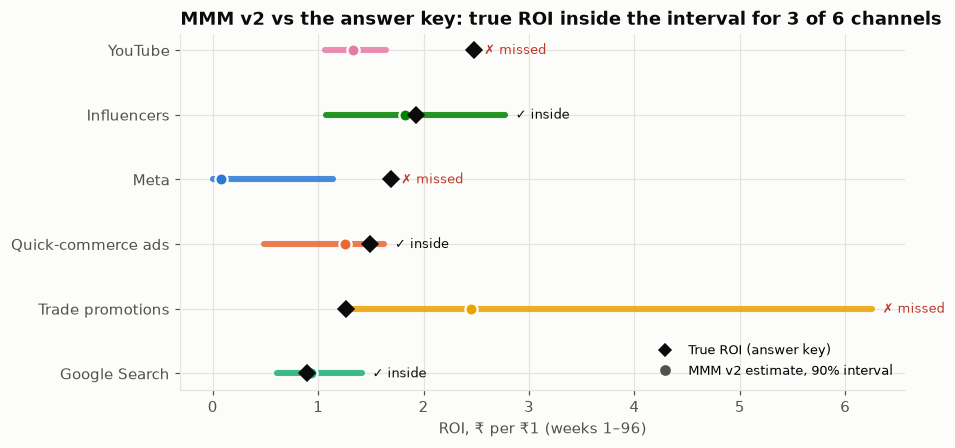

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
order = true96.sort_values().index
for j, n in enumerate(order):
    c = [k for k, v in LABEL.items() if v == n][0]
    ax.plot([v2.loc[n, "roi_lo"], v2.loc[n, "roi_hi"]], [j, j], color=COLOR[c], lw=4, solid_capstyle="round", alpha=0.85)
    ax.plot(v2.loc[n, "roi"], j, "o", color=COLOR[c], ms=8, mec="#fcfcfb", mew=1.5)
    ax.plot(true96[n], j, marker="D", color=INK, ms=7, ls="none")
    ax.text(max(v2.loc[n, "roi_hi"], true96[n]) + 0.1, j, "✓ inside" if detail.loc[n, "inside?"] else "✗ missed",
            va="center", fontsize=8.5, color=INK if detail.loc[n, "inside?"] else "#c0392b")
ax.plot([], [], "D", color=INK, label="True ROI (answer key)")
ax.plot([], [], "o", color=INK2, label="MMM v2 estimate, 90% interval")
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("ROI, ₹ per ₹1 (weeks 1–96)")
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
cov = g["MMM v2 (wk 1–96 + experiment)"]["coverage"]
ax.set_title(f"MMM v2 vs the answer key: true ROI inside the interval for {cov} channels")
save(fig, "10_v2_vs_truth"); plt.show()

## 4. The decision quantity: marginal ROI
Budget moves depend on the *next* rupee, not the average. Does v2 rank channels' marginal returns correctly?

In [7]:
mcmp = pd.DataFrame({"v2 marginal ROI": v2.mroi, "true marginal ROI": true_mroi})
rho_m = spearmanr(mcmp.iloc[:, 0], mcmp.iloc[:, 1]).correlation
print(f"Spearman, marginal ROI ranking (v2 vs truth): {rho_m:.2f}")
mcmp.sort_values("true marginal ROI", ascending=False).round(2)

Spearman, marginal ROI ranking (v2 vs truth): 0.09


,v2 marginal ROI,true marginal ROI
YouTube,3.23,4.10
Influencers,3.40,1.47
Trade promotions,0.70,0.52
Quick-commerce ads,0.45,0.50
Meta,0.03,0.45
Google Search,4.59,0.39


## 5. Why the misses? Evidence, not excuses
**Meta.** The truth makes Meta *near saturation*: today's spend sits far up its curve. A saturated
channel's weekly contribution barely moves when spend moves. Then a model cannot tell it apart from
baseline sales, and Meta's spend also tracks the growth trend. Test: how much does each channel's
*true* weekly contribution vary, and how closely does it follow the trend?

In [8]:
tot = {c: ex["contrib"][c].sum(0)[:96] for c in CHANNELS}
trend = np.arange(96)
ev = pd.DataFrame({
    "true contribution, week-to-week variation (CV)": {LABEL[c]: np.std(np.diff(v)) / np.mean(v) for c, v in tot.items()},
    "correlation with time trend": {LABEL[c]: np.corrcoef(v, trend)[0, 1] for c, v in tot.items()},
    "true k_rel (lower = more saturated)": {LABEL[c]: truth["channels"][c]["k_rel"] for c in CHANNELS},
})
ev.round(3)

,"true contribution, week-to-week variation (CV)",correlation with time trend,true k_rel (lower = more saturated)
Meta,0.027,0.735,0.460
Quick-commerce ads,0.069,0.609,0.664
Google Search,0.058,0.713,0.896
Trade promotions,1.082,0.092,0.973
YouTube,0.143,0.189,2.021
Influencers,0.078,0.648,1.449


**Where did the missing credit go?** Compare true and modelled contribution channel by channel.
Credit the model does not give to media stays in the baseline (intercept + trend).

In [9]:
units = ex["media_units"](ex["actual"])
credit = pd.DataFrame({"true ₹ Cr (wk 1–96)": {LABEL[c]: ex["contrib"][c][:, :96].sum() / 100 for c in CHANNELS},
                       "MMM v2 ₹ Cr": v2.contribution_cr})
credit["gap ₹ Cr"] = credit["MMM v2 ₹ Cr"] - credit["true ₹ Cr (wk 1–96)"]
credit.loc["All media"] = credit.sum()
print(f"Media truly drove ₹{credit.loc['All media', 'true ₹ Cr (wk 1–96)']:.1f} Cr; v2 credited ₹{credit.loc['All media', 'MMM v2 ₹ Cr']:.1f} Cr. "
      f"The missing ₹{-credit.loc['All media', 'gap ₹ Cr']:.1f} Cr sits in v2's baseline.")
credit.round(1)

Media truly drove ₹84.3 Cr; v2 credited ₹58.3 Cr. The missing ₹26.0 Cr sits in v2's baseline.


,true ₹ Cr (wk 1–96),MMM v2 ₹ Cr,gap ₹ Cr
Meta,22.7,1.1,-21.6
Quick-commerce ads,17.2,14.5,-2.7
Google Search,7.1,7.4,0.3
Trade promotions,8.0,15.5,7.5
YouTube,19.3,10.4,-9.0
Influencers,10.0,9.5,-0.5
All media,84.3,58.3,-26.0


**Trade promotions.** Hypothesis: the model measured the promotion *spike* and missed the pull-forward
(sales borrowed from the next two weeks). Test: the true *gross* ROI before pull-forward.

In [10]:
c = "trade_promo"
gross_roi = ex["beta"][c] * units[c][1][:, :96].sum() / ex["actual"][c][:, :96].sum()
print(f"Trade promotions: true GROSS ROI {gross_roi:.2f}, true NET ROI {true96['Trade promotions']:.2f} "
      f"(pull-forward {truth['channels'][c]['pull_forward']:.0%}); v2 estimated {v2.loc['Trade promotions', 'roi']:.2f}.")
print(f"v2's 'week after a promotion' control was too crude: promotions ran in {nat.loc[1:96, 'promo_flag'].mean():.0%} of weeks, "
      "often back to back, so clean post-promotion weeks were rare, and the dip is spread over two weeks.")

Trade promotions: true GROSS ROI 2.28, true NET ROI 1.26 (pull-forward 44%); v2 estimated 2.45.
v2's 'week after a promotion' control was too crude: promotions ran in 47% of weeks, often back to back, so clean post-promotion weeks were rare, and the dip is spread over two weeks.


**YouTube.** True half-life is long and the curve S-shaped; v2's half-life and curve can be compared
directly.

In [11]:
dd = np.load(ROOT / "model" / "mmm_v2_posterior_params.npz", allow_pickle=True)
hl = np.log(0.5) / np.log(np.clip(dd["alpha"], 1e-6, 0.999999))
hl_tbl = pd.DataFrame({"true half-life": {LABEL[c]: truth["channels"][c]["half_life"] for c in CHANNELS},
                       "v2 median": {LABEL[c]: np.median(hl[:, i]) for i, c in enumerate(CHANNELS)},
                       "v2 5%": {LABEL[c]: np.quantile(hl[:, i], .05) for i, c in enumerate(CHANNELS)},
                       "v2 95%": {LABEL[c]: np.quantile(hl[:, i], .95) for i, c in enumerate(CHANNELS)}})
hl_tbl["inside?"] = (hl_tbl["true half-life"] >= hl_tbl["v2 5%"]) & (hl_tbl["true half-life"] <= hl_tbl["v2 95%"])
hl_tbl.round(2)

,true half-life,v2 median,v2 5%,v2 95%,inside?
Meta,1.97,0.42,0.17,1.32,False
Quick-commerce ads,0.58,0.48,0.18,3.59,True
Google Search,0.38,1.53,0.69,2.15,False
Trade promotions,0.41,0.20,0.11,0.30,False
YouTube,4.79,5.41,3.88,7.23,True
Influencers,2.49,3.08,1.85,5.15,True


## 6. The geo experiment vs the truth

In [12]:
er = json.loads((ROOT / "model" / "experiment_result.json").read_text())
t_roi = exp_truth["true_test_roi"]
print(f"Experiment estimate {er['roi']:.3f} (90% CI {er['roi_ci90'][0]:.3f}–{er['roi_ci90'][1]:.3f}) vs true {t_roi:.3f}: "
      f"{'inside' if er['roi_ci90'][0] <= t_roi <= er['roi_ci90'][1] else 'outside'} the interval, error {er['roi'] / t_roi - 1:+.1%}")
print(f"Revenue lost: estimated ₹{er['revenue_lost_lakh']:.1f} lakh vs true ₹{exp_truth['true_revenue_lost_in_treated_geos_lakh']:.1f} lakh; "
      f"spend withheld: estimated ₹{er['spend_withheld_lakh']:.1f} lakh vs true ₹{exp_truth['true_spend_withheld_lakh']:.1f} lakh")

Experiment estimate 1.106 (90% CI 1.059–1.154) vs true 1.119: inside the interval, error -1.2%
Revenue lost: estimated ₹43.5 lakh vs true ₹42.9 lakh; spend withheld: estimated ₹39.4 lakh vs true ₹38.3 lakh


## 7. Customer lifetime value vs the truth

In [13]:
clv = pd.read_csv(ROOT / "model" / "clv_by_channel.csv", index_col=0)
lab = {"organic": "Organic", **LABEL}
tc = pd.Series({lab[k]: v["clv_24m_inr"] for k, v in truth["true_clv_by_channel"].items()})
clv_g = pd.DataFrame({"true 24m CLV ₹": tc, "estimate ₹": clv["CLV 24m ₹"], "low": clv["CLV 24m low"], "high": clv["CLV 24m high"]}).dropna()
clv_g["error"] = clv_g["estimate ₹"] / clv_g["true 24m CLV ₹"] - 1
clv_g["inside?"] = (clv_g["true 24m CLV ₹"] >= clv_g.low) & (clv_g["true 24m CLV ₹"] <= clv_g.high)
print(f"CLV: mean absolute error {clv_g.error.abs().mean():.1%}; ranking Spearman "
      f"{spearmanr(clv_g['estimate ₹'], clv_g['true 24m CLV ₹']).correlation:.2f}; inside interval {clv_g['inside?'].sum()} of {len(clv_g)}")
clv_g.round(3)

CLV: mean absolute error 2.0%; ranking Spearman 1.00; inside interval 6 of 6


,true 24m CLV ₹,estimate ₹,low,high,error,inside?
Google Search,800.2,831.036,792.823,875.266,0.039,True
Influencers,1027.7,1034.648,997.604,1081.617,0.007,True
Meta,726.2,717.093,700.329,735.657,-0.013,True
Organic,841.8,842.515,832.739,852.392,0.001,True
Trade promotions,442.3,429.668,415.570,448.676,-0.029,True
YouTube,883.4,909.709,880.883,940.015,0.030,True


## 8. Fake-influencer detector (AI3) vs the sealed fake list

In [14]:
flags = pd.read_csv(ROOT / "model" / "influencer_flags.csv")
fakes = set(truth["influencer_fake_creators"])
flags["is_fake"] = flags.creator_id.isin(fakes)
rows = {}
for m in ["flag_rule", "flag_if_5", "flag_if_10", "flag_if_15"]:
    sel = flags[m]
    rows[m] = dict(flagged=int(sel.sum()), true_fakes_caught=int((sel & flags.is_fake).sum()),
                   precision=(sel & flags.is_fake).sum() / max(sel.sum(), 1), recall=(sel & flags.is_fake).sum() / len(fakes))
k = len(fakes)
topk = flags.sort_values("anomaly_score", ascending=False).head(k)
rows[f"Isolation Forest, top {k} (precision@k)"] = dict(flagged=k, true_fakes_caught=int(topk.is_fake.sum()),
                                                       precision=topk.is_fake.mean(), recall=topk.is_fake.sum() / len(fakes))
fraud = pd.DataFrame(rows).T
print(f"{len(fakes)} fake creators in the truth ({truth['influencer_fake_spend_share']:.1%} of influencer spend).")
fraud.round(3)

13 fake creators in the truth (4.7% of influencer spend).


,flagged,true_fakes_caught,precision,recall
flag_rule,11.0,6.0,0.545,0.462
flag_if_5,8.0,8.0,1.000,0.615
flag_if_10,15.0,13.0,0.867,1.000
flag_if_15,22.0,13.0,0.591,1.000
"Isolation Forest, top 13 (precision@k)",13.0,13.0,1.000,1.000


In [15]:
fs = truth["influencer_fake_spend_share"]
print(f"Influencer ROI on all spend: true {true96['Influencers']:.2f}. On genuine spend only: {true96['Influencers'] / (1 - fs):.2f} "
      f"(+{fs / (1 - fs):.1%}). Removing the flagged creators recovers that waste.")

Influencer ROI on all spend: true 1.93. On genuine spend only: 2.02 (+4.9%). Removing the flagged creators recovers that waste.


## 9. Checkout A/B test vs the truth

In [16]:
s = pd.read_csv(FULL / "cro_sessions.csv")
gA, gB = s[s.variant == "A_three_step"].converted, s[s.variant == "B_one_page"].converted
diff = gB.mean() - gA.mean()
se = np.sqrt(gA.var() / len(gA) + gB.var() / len(gB))
t_lift = truth["cro"]["true_abs_lift"]
print(f"Estimated lift {diff * 100:+.2f} pp (95% CI {(diff - 1.96 * se) * 100:+.2f} to {(diff + 1.96 * se) * 100:+.2f}) vs true "
      f"{t_lift * 100:+.2f} pp: {'inside' if diff - 1.96 * se <= t_lift <= diff + 1.96 * se else 'outside'} the interval. "
      "(Conversion differs by device in the data, so the overall true lift is approximate.)")

Estimated lift +0.34 pp (95% CI +0.13 to +0.54) vs true +0.27 pp: inside the interval. (Conversion differs by device in the data, so the overall true lift is approximate.)


## 10. The frozen ₹24 Cr recommendation, valued with the TRUE response curves
Each plan is replayed through the real (sealed) generator over a year shaped like year 2. Margins and
customer-value weights are kept as the optimiser used them; only the curves are swapped for the truth.
The **oracle** is the best split anyone could have chosen knowing the truth, under the same ±50% limits.

In [17]:
rec = json.loads((ROOT / "model" / "optimiser_recommendation.json").read_text())
cur = np.array([rec["current_cr"][LABEL[c]] for c in CHANNELS])
plans = {"Today (₹33.5 Cr)": cur, "Pro-rata cut (₹24 Cr)": np.array([rec["pro_rata_cr"][LABEL[c]] for c in CHANNELS]),
         "Frozen recommendation (₹24 Cr)": np.array([rec["optimised_cr"][LABEL[c]] for c in CHANNELS])}
planned = ex["planned"]
beta = ex["beta"]
plan_y2 = {c: planned[c][:, 52:].sum() / 100 for c in CHANNELS}              # ₹ Cr in year 2 (plan)
MARGIN = {c: (0.30 if c == "qc_ads" else 0.37) for c in CHANNELS}
# customer-value weights exactly as the frozen optimiser used them
nbj = json.loads((ROOT / "notebooks" / "04_budget_optimiser.ipynb").read_text())
fv_txt = next("".join(o["data"]["text/plain"]) for c in nbj["cells"] for o in c.get("outputs", [])
              if "future value per ₹ revenue" in "".join(o.get("data", {}).get("text/plain", "")))
FV = {c: float(re.search(rf"{re.escape(LABEL[c])}\s+[\d.]+\s+([\d.]+)", fv_txt).group(1)) for c in CHANNELS}

def true_value(annual_cr):
    """True CLV-adjusted contribution after marketing, ₹ Cr, for an annual allocation by channel."""
    sp = {c: planned[c].copy() for c in CHANNELS}
    for i, c in enumerate(CHANNELS):
        sp[c][:, 52:] *= annual_cr[i] / plan_y2[c]
    units = ex["media_units"](sp)
    rev = np.array([beta[c] * units[c][0][:, 52:].sum() / 100 for c in CHANNELS])     # ₹ Cr incremental revenue
    return float((rev * np.array([MARGIN[c] + FV[c] for c in CHANNELS])).sum() - annual_cr.sum()), rev

vals = {k: true_value(v)[0] for k, v in plans.items()}
lo, hi = cur * 0.5, cur * 1.5
best, best_v = None, -np.inf
rng = np.random.default_rng(3)
starts = [plans["Frozen recommendation (₹24 Cr)"], plans["Pro-rata cut (₹24 Cr)"]] + \
         [lo + rng.dirichlet(np.ones(6)) * (24 - lo.sum()) for _ in range(15)]
for x0 in starts:
    r = minimize(lambda x: -true_value(x)[0], np.clip(x0, lo, hi), method="SLSQP", bounds=list(zip(lo, hi)),
                 constraints=[{"type": "eq", "fun": lambda x: x.sum() - 24}], options={"maxiter": 300})
    if r.success and -r.fun > best_v:
        best, best_v = r.x, -r.fun
vals["Oracle (best possible, ₹24 Cr)"] = best_v
vt = pd.Series(vals).to_frame("true net contribution ₹ Cr/yr")
gap_total = vals["Oracle (best possible, ₹24 Cr)"] - vals["Pro-rata cut (₹24 Cr)"]
captured = (vals["Frozen recommendation (₹24 Cr)"] - vals["Pro-rata cut (₹24 Cr)"]) / gap_total
alloc_cmp = pd.DataFrame({"frozen recommendation ₹ Cr": plans["Frozen recommendation (₹24 Cr)"], "oracle ₹ Cr": best},
                         index=[LABEL[c] for c in CHANNELS])
print(f"Predicted gain over pro-rata (frozen, from MMM v2): ₹{rec['expected_gain_vs_pro_rata_cr']['median']:.1f} Cr "
      f"(90% {rec['expected_gain_vs_pro_rata_cr']['p5']:.1f}–{rec['expected_gain_vs_pro_rata_cr']['p95']:.1f})")
print(f"TRUE gain over pro-rata: ₹{vals['Frozen recommendation (₹24 Cr)'] - vals['Pro-rata cut (₹24 Cr)']:.1f} Cr | "
      f"oracle gain: ₹{gap_total:.1f} Cr | recommendation captures {captured:.0%} of the best possible gain")
display_tbl = pd.concat([vt.round(2), alloc_cmp.round(2)], axis=0)
vt.round(2)

Predicted gain over pro-rata (frozen, from MMM v2): ₹10.1 Cr (90% 6.9–12.9)
TRUE gain over pro-rata: ₹5.9 Cr | oracle gain: ₹5.9 Cr | recommendation captures 100% of the best possible gain


,true net contribution ₹ Cr/yr
Today (₹33.5 Cr),-12.98
Pro-rata cut (₹24 Cr),-7.89
Frozen recommendation (₹24 Cr),-2.02
"Oracle (best possible, ₹24 Cr)",-2.02


In [18]:
alloc_cmp.round(2)

,frozen recommendation ₹ Cr,oracle ₹ Cr
Meta,4.20,4.26
Quick-commerce ads,4.15,4.15
Google Search,2.52,2.52
Trade promotions,2.18,2.18
YouTube,6.04,6.04
Influencers,4.90,4.85


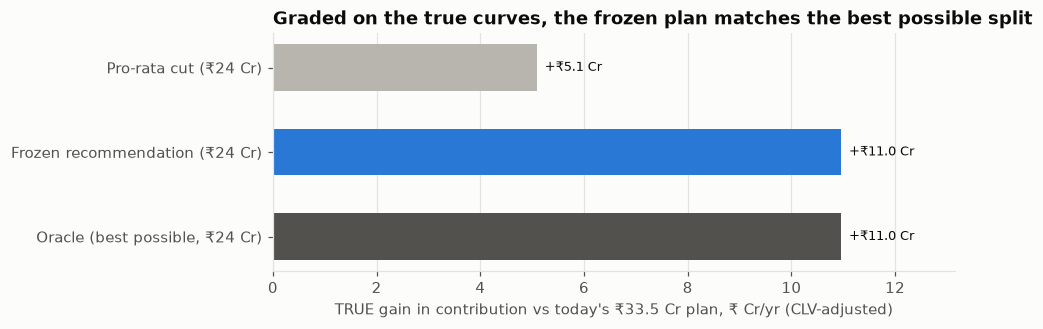

In [19]:
base = vals["Today (₹33.5 Cr)"]
names = [n for n in vals if not n.startswith("Today")]
gains = [vals[n] - base for n in names]
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(range(len(names)), gains, color=[NEUTRAL, COLOR["meta"], INK2], height=0.55)
for j, gv in enumerate(gains):
    ax.text(gv + 0.15, j, f"+₹{gv:.1f} Cr", va="center", fontsize=8.5, color=INK)
ax.set_yticks(range(len(names)), names); ax.invert_yaxis()
ax.set_xlim(0, max(gains) * 1.2)
ax.set_xlabel("TRUE gain in contribution vs today's ₹33.5 Cr plan, ₹ Cr/yr (CLV-adjusted)")
ax.grid(axis="y", visible=False)
ax.set_title(f"Graded on the true curves, the frozen plan matches the best possible split")
save(fig, "10_plan_vs_oracle"); plt.show()

## 11. Scorecard and so what

In [20]:
v2g = g["MMM v2 (wk 1–96 + experiment)"]
card = pd.DataFrame([
    ("MMM v2: true ROI inside 90% interval (≥5 of 6)", v2g["coverage"], "PASS" if v2g["coverage_pass"] else "FAIL"),
    ("MMM v2: ranking Spearman ≥0.8, top and bottom correct", f"ρ = {v2g['spearman']}", "PASS" if v2g["rank_pass"] else "FAIL"),
    ("MMM v2: holdout MAPE < 10%", f"{v2g['holdout_mape']:.1%}", "PASS" if v2g["mape_pass"] else "FAIL"),
    ("MMM v2: marginal-ROI ranking (added check, not pre-registered)", f"ρ = {rho_m:.2f}", "PASS" if rho_m >= 0.8 else "FAIL"),
    ("Geo experiment: truth inside 90% CI", f"{er['roi']:.2f} vs {t_roi:.2f}", "PASS" if er['roi_ci90'][0] <= t_roi <= er['roi_ci90'][1] else "FAIL"),
    ("CLV: mean absolute error < 10%", f"{clv_g.error.abs().mean():.1%}", "PASS" if clv_g.error.abs().mean() < 0.10 else "FAIL"),
    ("Fraud detector: precision@k", f"{fraud.iloc[-1].precision:.0%}", "—"),
    ("Checkout test: truth inside 95% CI", f"{diff * 100:+.2f} vs {t_lift * 100:+.2f} pp", "PASS" if diff - 1.96 * se <= t_lift <= diff + 1.96 * se else "FAIL"),
    ("Budget recommendation: share of best possible gain captured", f"{captured:.0%}", "—"),
    ("Budget recommendation: predicted gain vs true gain", f"₹{rec['expected_gain_vs_pro_rata_cr']['median']:.1f} vs ₹{vals['Frozen recommendation (₹24 Cr)'] - vals['Pro-rata cut (₹24 Cr)']:.1f} Cr", "OVERSTATED"),
], columns=["Test", "Result", "Verdict"])
card.to_csv(ROOT / "reports" / "validation_scorecard.csv", index=False)
card

,Test,Result,Verdict
0,MMM v2: true ROI inside 90% interval (≥5 of 6),3 of 6,FAIL
1,"MMM v2: ranking Spearman ≥0.8, top and bottom ...",ρ = 0.14,FAIL
2,MMM v2: holdout MAPE < 10%,3.2%,PASS
3,"MMM v2: marginal-ROI ranking (added check, not...",ρ = 0.09,FAIL
4,Geo experiment: truth inside 90% CI,1.11 vs 1.12,PASS
5,CLV: mean absolute error < 10%,2.0%,PASS
6,Fraud detector: precision@k,100%,—
7,Checkout test: truth inside 95% CI,+0.34 vs +0.27 pp,PASS
8,Budget recommendation: share of best possible ...,100%,—
9,Budget recommendation: predicted gain vs true ...,₹10.1 vs ₹5.9 Cr,OVERSTATED


In [21]:
missed = detail.index[~detail["inside?"]].tolist()
pred = rec["expected_gain_vs_pro_rata_cr"]
true_gain = vals["Frozen recommendation (₹24 Cr)"] - vals["Pro-rata cut (₹24 Cr)"]
print("SO WHAT")
print(f"1. MMM v2 failed its own pre-registered test: true ROI inside the interval for {v2g['coverage']} channels "
      f"(missed: {', '.join(missed)}), ranking ρ = {v2g['spearman']}, marginal-ROI ranking ρ = {rho_m:.2f}. "
      "Reported as is; nothing was re-tuned after opening the key.")
print(f"2. The misses have identifiable causes. Meta is near saturation (true k_rel {truth['channels']['meta']['k_rel']:.2f}), so its "
      f"contribution is almost flat and tracks the trend; v2 put ₹{credit.loc['Meta', 'true ₹ Cr (wk 1–96)'] - credit.loc['Meta', 'MMM v2 ₹ Cr']:.0f} Cr of "
      f"Meta's effect into baseline. Trade promotions: v2 measured the gross spike ({gross_roi:.2f} true gross vs {v2.loc['Trade promotions', 'roi']:.2f} "
      f"estimated) and missed the {truth['channels']['trade_promo']['pull_forward']:.0%} pull-forward.")
print(f"3. What held: the experiment ({er['roi']:.2f} vs true {t_roi:.2f}), CLV (error {clv_g.error.abs().mean():.0%}), the fraud detector "
      f"({fraud.loc['flag_if_10', 'true_fakes_caught']:.0f} of {len(fakes)} fakes at the 10% setting) and the checkout test.")
print(f"4. The budget plan matched the best possible split (captures {captured:.0%} of the achievable gain), but partly because the "
      f"±50% limits forced the same corners: four channels truly have low marginal returns (0.39–0.52) and YouTube high (4.10). "
      f"The predicted gain was overstated: ₹{pred['median']:.1f} Cr predicted (90% {pred['p5']:.1f}–{pred['p95']:.1f}) vs ₹{true_gain:.1f} Cr true.")
print("5. Next experiment: a Meta geo holdout. Meta is the largest budget line and the model's biggest miss, and an experiment is "
      "the reliable fix for a saturated, always-on channel; its result should feed MMM v3.")

SO WHAT
1. MMM v2 failed its own pre-registered test: true ROI inside the interval for 3 of 6 channels (missed: Meta, Trade promotions, YouTube), ranking ρ = 0.14, marginal-ROI ranking ρ = 0.09. Reported as is; nothing was re-tuned after opening the key.
2. The misses have identifiable causes. Meta is near saturation (true k_rel 0.46), so its contribution is almost flat and tracks the trend; v2 put ₹22 Cr of Meta's effect into baseline. Trade promotions: v2 measured the gross spike (2.28 true gross vs 2.45 estimated) and missed the 44% pull-forward.
3. What held: the experiment (1.11 vs true 1.12), CLV (error 2%), the fraud detector (13 of 13 fakes at the 10% setting) and the checkout test.
4. The budget plan matched the best possible split (captures 100% of the achievable gain), but partly because the ±50% limits forced the same corners: four channels truly have low marginal returns (0.39–0.52) and YouTube high (4.10). The predicted gain was overstated: ₹10.1 Cr predicted (90% 6.9–12.